# How much demand can each town take?

The CARLA campaign runs one operating point: 30 requests, one per 90 s, on
five towns. It answers *does the recommendation transfer*. It does not answer
**where each town stops coping**, which is the question this notebook exists
for.

The synthetic map already has that answer at capacity 40 — the insertion
advantage decays with load but never inverts, and the apparent crossover at
3 req/min turned out to be the service window rather than the load
(`synthetic-load-crossover.ipynb`). Whether that shape survives real geometry
is a different claim, because a real town's failure mode is *driving time*,
not seats.

## What is swept, and what is not

**Only the arrival rate moves.** Capacity stays 20, the window and patience
stay 750 s, the request count stays 30, the policies stay the same three.
Towns differ in size and that variation is the finding, exactly as in the
campaign — an identical scenario is easy in Town02 and hard in Town05.

The ladder is deliberately the **same five rates the synthetic sweep used**,
so the two are read side by side in section 7:

| interval | 90 s | 60 s | 45 s | 30 s | 20 s |
|---|---|---|---|---|---|
| offered | 0.67/min | 1.00/min | 1.33/min | 2.00/min | 3.00/min |

90 s is the campaign's own operating point, so **that rung is already in the
store** and costs nothing to re-collect. The sweep only adds the four faster
ones.

!!! warning "Constant volume means the fast rungs are bursts, not sustained load"
    `MAX_REQUESTS` is held at 30 so that every arm carries the same demand
    *volume* and only its rate changes — the same choice the synthetic sweep
    made, and the reason capacity stays irrelevant here (mean occupancy is
    2–4 riders against 20 seats, so raising the rate cannot make seats bind
    when the total is only 30). The cost is that 3.00/min means "30 requests
    in 600 s and then quiet", not a rate the bus must hold indefinitely.
    Patience is what makes it a real test: at 750 s a rider abandoned during
    the burst is gone before the quiet tail arrives.

    To ask the sustained-load question instead, hold the arrival span fixed
    and raise `MAX_REQUESTS` with the rate. That is a different and more
    expensive experiment, and at the top of the ladder it would put ~25
    riders aboard, which reintroduces capacity as a second moving variable.

## What it reports

1. **A saturation guard**, so a coverage number is never read without knowing
   whether the bus was keeping up.
2. **Coverage against offered load, per town, per policy** — the headline.
3. **A breaking point per (town, policy)**: the fastest rung still served to
   the 80% gate.
4. **Whether the ranking survives the load**, which the campaign could only
   test at one rate.
5. **The same comparison against the synthetic sweep**, rung for rung.

## Running it

Needs a live server: `docker compose up -d`, then a minute. Sequential —
`CarlaBackend` sets `parallel_safe = False`. Everything lands in the store as
it completes, so **stopping and re-running resumes rather than restarts**.

## Configuration

In [1]:
# --- Towns ---------------------------------------------------------------
# The campaign's five, unchanged. All are prepared and calibrated; section 1
# verifies that rather than assuming it.
ALL_TOWNS = ["Town01", "Town02", "Town03", "Town05", "TAU"]

# --- The scenario, held identical to the campaign -------------------------
# Every one of these matches carla-campaign-towns.ipynb exactly, so the 90 s
# rung of this sweep IS the campaign's operating point and its runs are
# reused rather than repeated. Change any of them and that stops being true.
NPC_VEHICLES = 20
MAX_REQUESTS = 30
CAPACITY = 20
WINDOW = 750.0
PATIENCE = 750.0
DWELL_S = 10.0
FIXED_DELTA_S = 0.05
MAX_TIME = 40000.0

# --- The one variable under test -----------------------------------------
# Demand intervals in seconds, slowest first. 90 s is the campaign's rung and
# is already recorded; the other four are new work. The rates these give --
# 0.67, 1.00, 1.33, 2.00, 3.00 per minute -- are five of the six the
# synthetic sweep used, which is what makes section 7 a like-for-like read.
DEMAND_INTERVALS = [90.0, 60.0, 45.0, 30.0, 20.0]

# The campaign's rung, named so the code can say what it is reusing.
ANCHOR_INTERVAL = 90.0

# --- Sample size ---------------------------------------------------------
# Three seeds a rung. This is a shape-finding sweep, not a significance test:
# five rungs x five towns x three policies is already 225 trials, and the 5%
# CI bar deliberately lives on the synthetic map where a trial costs seconds.
# These are a subset of the campaign's range(10), so the anchor rung is
# already covered for every one of them.
SEEDS = list(range(3))

# --- Cost ----------------------------------------------------------------
# Measured per-trial wall minutes at the 90 s rung, averaged over the three
# policies of the 150 stored campaign runs. ETA only.
MEASURED_TRIAL_MINUTES = {"Town01": 5.20, "Town02": 4.29, "Town03": 5.27,
                          "Town05": 6.11, "TAU": 1.69}
DEFAULT_TRIAL_MINUTES = 5.0

# Wall time tracks simulated time, and simulated time is the arrival span
# plus a tail of roughly 900 s spent finishing off the last riders --
# measured across the stored runs, whose spans are 2700 s and whose sim times
# average ~3600 s. So a rung's cost scales as (30 x interval + 900) / 3600.
# ETA only: the progress bar's rolling mean corrects it within five trials.
SETTLING_TAIL_S = 900.0
ANCHOR_SIM_S = MAX_REQUESTS * ANCHOR_INTERVAL + SETTLING_TAIL_S

CARLA_HOST, CARLA_PORT = "localhost", 2000

In [2]:
def load_factor(interval_s: float) -> float:
    """
    How a rung's wall time scales against the anchor rung.

    :param interval_s: Demand interval in seconds.
    :return: Multiplier on the measured 90 s per-trial minutes.
    """
    return (MAX_REQUESTS * interval_s + SETTLING_TAIL_S) / ANCHOR_SIM_S


def expected_minutes(town: str, interval_s: float) -> float:
    """
    Estimated wall minutes for one trial.

    :param town: Town the trial runs in.
    :param interval_s: Demand interval in seconds.
    :return: Minutes, for the progress bar only.
    """
    base = MEASURED_TRIAL_MINUTES.get(town, DEFAULT_TRIAL_MINUTES)
    return base * load_factor(interval_s)


print(f"{len(ALL_TOWNS)} towns x 3 policies x {len(SEEDS)} seeds x "
      f"{len(DEMAND_INTERVALS)} rungs = "
      f"{len(ALL_TOWNS) * 3 * len(SEEDS) * len(DEMAND_INTERVALS)} trials")
print("offered demand: "
      + ", ".join(f"{60 / i:.2f}/min" for i in DEMAND_INTERVALS))

budget = sum(
    expected_minutes(town, interval) * 3 * len(SEEDS)
    for town in ALL_TOWNS for interval in DEMAND_INTERVALS
    if interval != ANCHOR_INTERVAL)
anchor = sum(
    expected_minutes(town, ANCHOR_INTERVAL) * 3 * len(SEEDS)
    for town in ALL_TOWNS)
print(f"\nestimated new work: {budget / 60:.1f} h")
print(f"reused from the campaign at {ANCHOR_INTERVAL:.0f} s: "
      f"{anchor / 60:.1f} h already spent")

5 towns x 3 policies x 3 seeds x 5 rungs = 225 trials
offered demand: 0.67/min, 1.00/min, 1.33/min, 2.00/min, 3.00/min

estimated new work: 7.8 h
reused from the campaign at 90 s: 3.4 h already spent


In [3]:
import statistics
import time

import matplotlib.pyplot as plt
import pandas as pd
from cycler import cycler
from tqdm.auto import tqdm

from src.algorithm.FixedRoutePolicy import FixedRoutePolicy
from src.algorithm.ReorderingInsertionPolicy import ReorderingInsertionPolicy
from src.algorithm.WindowInsertionPolicy import WindowInsertionPolicy
from src.experiment import run_campaign
from src.experiment.store import DEFAULT_RUNS_DIR, load_runs
from src.map.carla_stops import stops_path
from src.map.carla_topology import topology_path
from src.map.CarlaMapProvider import CarlaMapProvider
from src.simulation.CarlaBackend import (
    CarlaBackend, speed_limits_from, stop_positions_from,
)
from src.simulation.carla_world import (
    GENERATED_SPEED_CEILING_KPH, is_generated,
)

from IPython.display import Markdown, display

# The campaign's palette, so the two notebooks' charts are read together.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
SURFACE, INK, INK_SOFT, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE, "axes.prop_cycle": cycler(color=SERIES),
    "axes.edgecolor": INK_SOFT, "axes.labelcolor": INK_SOFT,
    "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelsize": 9, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": INK_SOFT,
    "ytick.color": INK_SOFT, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "figure.dpi": 110,
})

POLICY_LABELS = ["Fixed route", "Window W750", "Reordering W750"]
POLICIES = [
    ("Fixed route", lambda g: FixedRoutePolicy(g)),
    ("Window W750", lambda g: WindowInsertionPolicy(g, max_wait_s=WINDOW)),
    ("Reordering W750",
     lambda g: ReorderingInsertionPolicy(g, max_wait_s=WINDOW)),
]

# demand_interval_s is deliberately absent: it is the swept variable and is
# supplied per rung.
BASE_TRIAL = dict(
    max_requests=MAX_REQUESTS, capacity=CAPACITY, max_wait_s=PATIENCE,
    dwell_s=DWELL_S, max_time=MAX_TIME,
)

# The 80% fulfilment gate from the design review's §3.2.2. "Can handle this
# demand" is defined as clearing it, so that this sweep and the campaign
# answer to the same bar.
GATE = 80.0

## 1. Are the towns still prepared?  *(no server needed)*

Cheap, and it fails loudly rather than letting the sweep skip a town for
eleven hours and report four. A `traffic_efficiency` of 1.0 means
uncalibrated: run `carla-campaign-towns.ipynb` section 3 first.

In [4]:
def speed_limit_tag(town: str) -> str:
    """
    How this town's speed limits were derived, for the run identity.

    A shipped town publishes type-274 landmarks; a generated one has none,
    so its limits come from the .xodr's per-lane elements and are capped.
    The two are different procedures and must not pool -- which is also why
    this is a function rather than a literal: hardcoding the shipped town's
    tag in a filter silently drops every generated town's runs.

    :param town: Town name.
    :return: The identity tag for that town's speed-limit source.
    """
    if is_generated(town):
        return f"xodr-capped-{int(GENERATED_SPEED_CEILING_KPH)}-v1"
    return "landmark-harmonic-v1"


def readiness(town: str) -> dict:
    """
    Report whether one town can be swept.

    :param town: Town name.
    :return: A row describing what is present and what is not.
    """
    has_topology = topology_path(town).exists()
    has_stops = stops_path(town).exists()
    efficiency, stops, note = None, None, ""
    if has_topology and has_stops:
        try:
            provider = CarlaMapProvider(town)
            efficiency = provider.traffic_efficiency()
            stops = len(provider.get_stops())
            problems = provider.validate()
            note = "OK" if not problems else f"{len(problems)} map problems"
        except Exception as error:              # noqa: BLE001
            note = f"failed to load: {error!r}"
    return {
        "town": town,
        "topology": "yes" if has_topology else "MISSING",
        "stops": stops if stops is not None else (
            "yes" if has_stops else "MISSING"),
        "traffic_efficiency": efficiency if efficiency is not None else "—",
        "speed_limits": speed_limit_tag(town),
        "ready": "yes" if efficiency not in (None, 1.0) else "no",
        "note": note,
    }


display(pd.DataFrame([readiness(t) for t in ALL_TOWNS]).set_index("town"))

READY_TOWNS = [
    t for t in ALL_TOWNS
    if stops_path(t).exists() and topology_path(t).exists()
    and CarlaMapProvider(t).traffic_efficiency() != 1.0
]
print(f"ready to sweep: {READY_TOWNS}")
missing = [t for t in ALL_TOWNS if t not in READY_TOWNS]
if missing:
    display(Markdown(
        f"> **Not sweeping: {', '.join(missing)}.** Uncalibrated or missing "
        "an artifact — prepare it in `carla-campaign-towns.ipynb` "
        "sections 2–3 first."))

,topology,stops,traffic_efficiency,speed_limits,ready,note
town,,,,,,
Town01,yes,15,0.4757,landmark-harmonic-v1,yes,OK
Town02,yes,15,0.4478,landmark-harmonic-v1,yes,OK
Town03,yes,15,0.6274,landmark-harmonic-v1,yes,3 map problems
Town05,yes,15,0.3671,landmark-harmonic-v1,yes,OK
TAU,yes,25,0.6994,xodr-capped-50-v1,yes,34 map problems


ready to sweep: ['Town01', 'Town02', 'Town03', 'Town05', 'TAU']


## 2. Run the sweep  🖥 *needs a live server*

Rung-major within a town, and one `run_campaign` call per trial so a CARLA
hiccup costs one trial rather than the night. Anything already recorded is
skipped, so the 90 s rung comes back instantly from the campaign's runs and
re-running after an interruption resumes.

Three nested bars — towns, then rungs, then trials — with a rolling mean over
the last five trials, so the ETA reflects what the *current rung* costs
rather than what the slowest one did.

In [5]:
def world_for(town: str, provider: CarlaMapProvider) -> dict:
    """
    Build the store identity for one town's world.

    Identical to the campaign's, field for field, which is what lets the
    90 s rung reuse its runs. ``traffic_efficiency`` and the speed-limit,
    steering and routing tags are all in here because each changes what the
    bus does, and omitting one would let two different buses share an
    identity.

    :param town: Town name.
    :param provider: That town's loaded provider.
    :return: The world identity.
    """
    return {
        "town": town, "backend": "CarlaBackend",
        "npc_vehicles": NPC_VEHICLES, "fixed_delta_s": FIXED_DELTA_S,
        "no_rendering": True, "blueprint": "vehicle.volkswagen.t2_2021",
        "traffic_efficiency": provider.traffic_efficiency(),
        "speed_limits": speed_limit_tag(town),
        # v2 (2026-08-24): the bus's lateral PID gain went 1.95 ->
        # 0.75, to stop it slamming to full lock in junctions. That
        # changes leg times, so v1 and v2 runs must not pool.
        "steering": "direct-drive-v2",
        "routing": "time-lane-change-v1",
    }


def backend_factory_for(town: str, positions: dict, speed_for):
    """
    Build a per-seed world builder for one town.

    :param town: Town to drive in.
    :param positions: That town's stop coordinates.
    :param speed_for: That town's speed-limit lookup, so the planner prices
        legs in travel time exactly as TransitGraph does.
    :return: A function of seed returning a backend factory.
    """
    def for_seed(seed: int):
        def build(graph, start_stop_id: str) -> CarlaBackend:
            """Build the CARLA backend for one trial."""
            return CarlaBackend(
                stop_positions=positions, position=start_stop_id, town=town,
                speed_for=speed_for, lane_changes=True,
                host=CARLA_HOST, port=CARLA_PORT,
                fixed_delta_s=FIXED_DELTA_S, dwell_s=DWELL_S,
                npc_vehicles=NPC_VEHICLES, seed=seed, no_rendering=True,
                # CARLA results are not independent of server history: an
                # earlier campaign lost 7 Town05 runs to a back-to-back
                # trials artefact and had to be discarded.
                reload_world=True)
        return build
    return for_seed


RUN_SWEEP = True    # set False to skip; needs a live server

if RUN_SWEEP and not READY_TOWNS:
    display(Markdown("> **Nothing to run.** No town is prepared."))

if RUN_SWEEP and READY_TOWNS:
    failures, durations = [], []
    towns_bar = tqdm(READY_TOWNS, desc="towns", unit="town")
    for town in towns_bar:
        towns_bar.set_postfix_str(town)
        provider = CarlaMapProvider(town)
        positions = stop_positions_from(provider)
        world = world_for(town, provider)
        for_seed = backend_factory_for(
            town, positions, speed_limits_from(provider))

        rungs_bar = tqdm(DEMAND_INTERVALS, desc=f"  {town}", unit="rung",
                         leave=False)
        for interval in rungs_bar:
            rungs_bar.set_postfix_str(f"{60 / interval:.2f}/min")
            expected = expected_minutes(town, interval)
            trials_bar = tqdm(
                total=len(SEEDS) * len(POLICIES), unit="trial", leave=False,
                desc=f"    {60 / interval:.2f}/min")
            # Seed-major so the three policies of a seed finish together: an
            # interrupted run then leaves paired data rather than an orphan.
            for seed in SEEDS:
                for label, factory in POLICIES:
                    started = time.perf_counter()
                    ran = 0
                    try:
                        outcome = run_campaign(
                            policies=[(label, factory)], seeds=[seed],
                            world=world, directory=DEFAULT_RUNS_DIR,
                            provider=provider, backend_factory_for=for_seed,
                            n_jobs=1, progress=False,
                            demand_interval_s=interval, **BASE_TRIAL)
                        ran = outcome.ran
                    except Exception as error:      # noqa: BLE001
                        # Broad on purpose: a CARLA failure surfaces as
                        # almost anything, and losing the rest is worse.
                        failures.append((town, interval, seed, label,
                                         repr(error)))
                        tqdm.write(f"  {town} {60 / interval:.2f}/min "
                                   f"seed {seed} {label} FAILED: {error!r}")

                    elapsed = (time.perf_counter() - started) / 60
                    # A skipped trial costs no time; counting it would make
                    # the ETA nonsense for the rest of a resumed run.
                    if ran:
                        durations.append(elapsed)
                    rolling = (statistics.fmean(durations[-5:]) if durations
                               else expected)
                    trials_bar.update(1)
                    trials_bar.set_postfix_str(
                        f"seed {seed} {label}"
                        + ("" if ran else " (already recorded)")
                        + f" | rolling {rolling:.1f} min/trial, "
                          f"expected {expected:.1f}")
            trials_bar.close()
        rungs_bar.close()

    planned = len(READY_TOWNS) * len(DEMAND_INTERVALS) * len(SEEDS) * 3
    print(f"\ndone — {len(durations)} trials run, "
          f"{planned - len(durations)} skipped or failed, "
          f"{len(failures)} failures")
    for town, interval, seed, label, error in failures:
        print(f"  {town} {60 / interval:.2f}/min seed {seed} {label}: {error}")
elif not RUN_SWEEP:
    print("sweep skipped -- set RUN_SWEEP = True with a server up")

towns:   0%|          | 0/5 [00:00<?, ?town/s]

  Town01:   0%|          | 0/5 [00:00<?, ?rung/s]

    0.67/min:   0%|          | 0/9 [00:00<?, ?trial/s]

    1.00/min:   0%|          | 0/9 [00:00<?, ?trial/s]

    1.33/min:   0%|          | 0/9 [00:00<?, ?trial/s]

    2.00/min:   0%|          | 0/9 [00:00<?, ?trial/s]

... (22 outputs left out)

    1.33/min:   0%|          | 0/9 [00:00<?, ?trial/s]

    2.00/min:   0%|          | 0/9 [00:00<?, ?trial/s]

    3.00/min:   0%|          | 0/9 [00:00<?, ?trial/s]


done — 0 trials run, 225 skipped or failed, 0 failures


## 3. Collect

In [6]:
def collect() -> pd.DataFrame:
    """
    Read back every run belonging to this sweep.

    The filter mirrors the world identity exactly. ``speed_limits`` is
    checked per town rather than against a literal, because a generated town
    files under a different tag and a literal would silently drop it.

    :return: One row per run.
    """
    records = [
        r for r in load_runs(DEFAULT_RUNS_DIR,
                             where={"identity.world.backend": "CarlaBackend"})
        if r.identity.world.get("town") in ALL_TOWNS
        and r.identity.world.get("npc_vehicles") == NPC_VEHICLES
        and r.identity.world.get("speed_limits") == speed_limit_tag(
            r.identity.world.get("town"))
        and r.identity.world.get("steering") == "direct-drive-v2"
        and r.identity.world.get("routing") == "time-lane-change-v1"
        and r.identity.trial.get("max_requests") == MAX_REQUESTS
        and r.identity.trial.get("capacity") == CAPACITY
        and r.identity.trial.get("max_wait_s") == PATIENCE
        and r.identity.trial.get("demand_interval_s") in DEMAND_INTERVALS
        and r.identity.policy in POLICY_LABELS
        # The anchor rung has ten seeds stored from the campaign and the new
        # rungs have three. Taking all of them would estimate one point of
        # the ladder far better than the rest, and a step at that rung would
        # then be sampling rather than load. Raise SEEDS to range(10) and
        # the anchor fills in for free; the others would have to be run.
        and r.identity.seed in SEEDS
    ]
    rows = []
    for r in records:
        interval = r.identity.trial["demand_interval_s"]
        sim_s = r.backend_stats.get("ticks", 0) * FIXED_DELTA_S
        rows.append({
            "town": r.identity.world["town"], "policy": r.identity.policy,
            "seed": r.identity.seed, "interval_s": interval,
            "offered_per_min": 60.0 / interval,
            "served": r.kpi.served_fraction * 100,
            "wait": r.kpi.mean_wait_time, "ride": r.kpi.mean_ride_time,
            "throughput": r.kpi.throughput,
            "fulfilled": r.kpi.fulfilled_count,
            "cancelled": r.kpi.cancelled_count,
            "sim_s": sim_s,
            "distance_m": r.backend_stats.get("distance_m", 0.0),
            "red_s": r.backend_stats.get("red_light_ticks", 0)
            * FIXED_DELTA_S,
            # Under direct drive a repath means the bus was physically
            # stuck; the red-light and queueing exemptions cover the
            # legitimate stops.
            "repaths": r.backend_stats.get("repaths", 0),
            "unroutable": r.backend_stats.get("unroutable_legs", 0),
        })
    return pd.DataFrame(rows)


frame = collect()
HAVE_RUNS = not frame.empty

if not HAVE_RUNS:
    display(Markdown(
        "> **No runs yet.** Run section 2, or check that the world identity "
        "here matches what the runs were filed under."))
else:
    print(f"{len(frame)} runs, {frame['town'].nunique()} towns, "
          f"{frame['interval_s'].nunique()} rungs")
    coverage = frame.groupby(["town", "interval_s"]).size().unstack(
        fill_value=0)
    display(Markdown("**Runs per town and rung** — 9 is a complete cell "
                     "(3 policies x 3 seeds)."))
    display(coverage)

225 runs, 5 towns, 5 rungs


**Runs per town and rung** — 9 is a complete cell (3 policies x 3 seeds).

interval_s,20.0,30.0,45.0,60.0,90.0
town,,,,,
TAU,9,9,9,9,9
Town01,9,9,9,9,9
Town02,9,9,9,9,9
Town03,9,9,9,9,9
Town05,9,9,9,9,9


## 4. The saturation guard

A coverage number means one thing when the bus is keeping up and another
when it is not, and nothing in the campaign made the difference visible.

**Drain ratio** — simulated time over the arrival span. At 1.0 the bus
finished as the last request appeared; above it there was still work left
when demand stopped. Unlike the synthetic patient regime, an unserved rider
here *abandons* after 750 s rather than queueing forever, so this measures
how long the tail of work ran, not an unbounded backlog.

**Seats used**, by Little's law — `throughput x ride time`, against 20 seats.
This is the check that capacity is still not the binding constraint: the
campaign measured 1.6–3.6 riders aboard at 0.67/min, and if the fast rungs
stay well under 20 then everything below is about *driving time*, which is
what a real town contributes and the synthetic map cannot.

In [7]:
def saturation(runs: pd.DataFrame) -> pd.DataFrame:
    """
    Report how hard the bus was working at each rung.

    :param runs: Collected runs.
    :return: One row per town, rung and policy.
    """
    if runs.empty:
        return pd.DataFrame()
    rows = runs.groupby(["town", "offered_per_min", "policy"]).agg(
        drain_ratio=("sim_s", "mean"), throughput=("throughput", "mean"),
        ride_s=("ride", "mean"), interval_s=("interval_s", "mean"),
        n=("sim_s", "size")).reset_index()
    rows["drain_ratio"] = (rows["drain_ratio"]
                           / (MAX_REQUESTS * rows["interval_s"]))
    # Little's law: mean number aboard = arrival rate x time aboard.
    rows["seats_used"] = (100.0 * rows["throughput"] / 60.0 * rows["ride_s"]
                          / CAPACITY)
    return rows[["town", "offered_per_min", "policy", "drain_ratio",
                 "seats_used", "n"]]


if not HAVE_RUNS:
    display(Markdown("_Nothing to report until the sweep has run._"))
else:
    guard = saturation(frame)
    display(Markdown("**Drain ratio** — simulated time over arrival span."))
    display(guard.pivot_table(index=["town", "policy"],
                              columns="offered_per_min",
                              values="drain_ratio").round(2))
    display(Markdown(f"**Seats used (%)** against {CAPACITY} — if the worst "
                     "cell here stays well under 100, capacity is not what "
                     "is failing and the rest of this notebook is about "
                     "driving time."))
    display(guard.pivot_table(index=["town", "policy"],
                              columns="offered_per_min",
                              values="seats_used").round(1))
    worst = guard.loc[guard["seats_used"].idxmax()]
    print(f"busiest cell: {worst['town']} {worst['policy']} at "
          f"{worst['offered_per_min']:.2f}/min — "
          f"{worst['seats_used']:.1f}% of {CAPACITY} seats")

**Drain ratio** — simulated time over arrival span.

offered_per_min         0.666667  1.000000  1.333333  2.000000  3.000000
town   policy                                                           
TAU    Fixed route          1.53      1.60      1.79      2.72      4.12
       Reordering W750      1.24      1.50      1.75      2.28      3.13
       Window W750          1.25      1.53      1.68      2.21      3.18
Town01 Fixed route          1.38      1.55      1.95      2.29      2.99
       Reordering W750      1.33      1.51      1.71      2.05      2.96
       Window W750          1.32      1.56      1.80      2.24      3.02
Town02 Fixed route          1.32      1.45      1.66      2.07      2.76
       Reordering W750      1.14      1.28      1.48      1.89      2.36
       Window W750          1.14      1.30      1.50      1.89      2.42
Town03 Fixed route          1.43      1.55      1.96      2.40      3.45
       Reordering W750      1.26      1.43      1.66      2.22      2.99
       Window W750          1.33      1.47      1.67      2.33      2.70
Town05 Fixed route          1.39      1.85      2.30      2.65      3.74
       Reordering W750      1.37      1.58      1.83      2.39      2.91
       Window W750          1.37      1.75      2.02      2.40      3.32

**Seats used (%)** against 20 — if the worst cell here stays well under 100, capacity is not what is failing and the rest of this notebook is about driving time.

offered_per_min         0.666667  1.000000  1.333333  2.000000  3.000000
town   policy                                                           
TAU    Fixed route          12.3      11.0      20.0      31.3      33.6
       Reordering W750      13.3      19.0      22.8      29.5      35.5
       Window W750          14.4      20.2      23.4      30.8      35.9
Town01 Fixed route          12.7      22.2      22.9      23.4      28.9
       Reordering W750      12.3      16.7      23.2      29.0      29.1
       Window W750          12.9      17.4      25.1      25.1      31.8
Town02 Fixed route          14.4      19.5      22.7      28.9      30.9
       Reordering W750       7.6      12.7      16.6      23.4      26.0
       Window W750           8.4      12.9      15.2      18.2      26.7
Town03 Fixed route          14.2      21.0      24.2      24.0      28.4
       Reordering W750      11.8      19.4      19.2      30.8      29.4
       Window W750          11.6      18.9      19.9      22.4      26.0
Town05 Fixed route          14.4      17.8      18.2      29.2      34.0
       Reordering W750      17.4      19.1      19.6      24.9      33.4
       Window W750          16.5      22.8      22.1      30.3      35.1

busiest cell: TAU Window W750 at 3.00/min — 35.9% of 20 seats


## 5. Where demand can be handled

The headline. One panel per town, coverage against offered load, with the
80% gate drawn. A line that stays above the dashes is a (town, policy) pair
that copes across the whole ladder; one that crosses it has a breaking point,
and where it crosses is the answer this notebook was built for.

Read the panels against each other, not just individually: the towns differ
by size and red-light density, so the *spacing* between the curves is what
says whether routing buys more headroom on a hard map or an easy one.

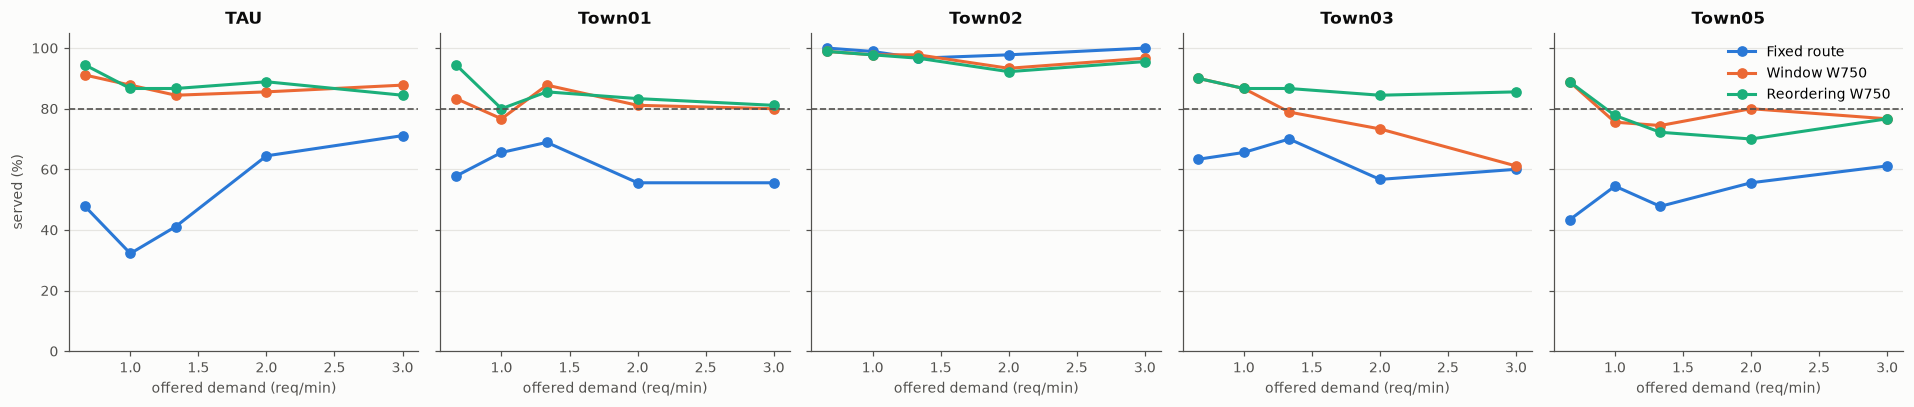

**Mean coverage (%)**

offered_per_min         0.666667  1.000000  1.333333  2.000000  3.000000
town   policy                                                           
TAU    Fixed route          47.8      32.2      41.1      64.4      71.1
       Reordering W750      94.4      86.7      86.7      88.9      84.4
       Window W750          91.1      87.8      84.4      85.6      87.8
Town01 Fixed route          57.8      65.6      68.9      55.6      55.6
       Reordering W750      94.4      80.0      85.6      83.3      81.1
       Window W750          83.3      76.7      87.8      81.1      80.0
Town02 Fixed route         100.0      98.9      96.7      97.8     100.0
       Reordering W750      98.9      97.8      96.7      92.2      95.6
       Window W750          98.9      97.8      97.8      93.3      96.7
Town03 Fixed route          63.3      65.6      70.0      56.7      60.0
       Reordering W750      90.0      86.7      86.7      84.4      85.6
       Window W750          90.0      86.7      78.9      73.3      61.1
Town05 Fixed route          43.3      54.4      47.8      55.6      61.1
       Reordering W750      88.9      77.8      72.2      70.0      76.7
       Window W750          88.9      75.6      74.4      80.0      76.7

In [8]:
if not HAVE_RUNS:
    display(Markdown("_Nothing to report until the sweep has run._"))
else:
    towns = sorted(frame["town"].unique())
    figure, axes = plt.subplots(
        1, len(towns), figsize=(3.5 * len(towns), 3.8), sharey=True,
        squeeze=False)
    for axis, town in zip(axes[0], towns):
        block = frame[frame["town"] == town]
        for colour, label in zip(SERIES, POLICY_LABELS):
            series = (block[block["policy"] == label]
                      .groupby("offered_per_min")["served"].mean()
                      .sort_index())
            if series.empty:
                continue
            axis.plot(series.index, series.values, marker="o", markersize=6,
                      lw=2.0, color=colour, label=label)
        axis.axhline(GATE, ls="--", lw=1.1, color=INK_SOFT)
        axis.set_title(town)
        axis.set_xlabel("offered demand (req/min)")
        axis.set_ylim(0, 105)
        axis.grid(axis="y")
        axis.set_axisbelow(True)
    axes[0][0].set_ylabel("served (%)")
    axes[0][-1].legend()
    figure.tight_layout()
    plt.show()

    display(Markdown("**Mean coverage (%)**"))
    display(frame.pivot_table(index=["town", "policy"],
                              columns="offered_per_min",
                              values="served").round(1))

In [9]:
def breaking_point(runs: pd.DataFrame, gate: float = GATE) -> pd.DataFrame:
    """
    The fastest rung each (town, policy) still serves to the gate.

    Reported as a rung of the ladder rather than an interpolated crossing:
    at three seeds a rung the ladder is the honest resolution.

    :param runs: Collected runs.
    :param gate: Fulfilment percentage that counts as coping.
    :return: One row per town and policy.
    """
    if runs.empty:
        return pd.DataFrame()
    means = (runs.groupby(["town", "policy", "offered_per_min"])["served"]
             .mean().reset_index())
    rows = []
    for (town, policy), group in means.groupby(["town", "policy"]):
        ladder = group.sort_values("offered_per_min")
        passing = ladder[ladder["served"] >= gate]
        failing = ladder[ladder["served"] < gate]
        if passing.empty:
            verdict = f"never — fails from {ladder.iloc[0]['served']:.0f}%"
            handled = float("nan")
        elif failing.empty:
            handled = passing["offered_per_min"].max()
            verdict = (f"whole ladder to {handled:.2f}/min"
                       if len(ladder) > 1
                       else f"only one rung run ({handled:.2f}/min)")
        else:
            handled = passing["offered_per_min"].max()
            first_fail = failing["offered_per_min"].min()
            verdict = (f"{handled:.2f}/min — fails at {first_fail:.2f}"
                       if first_fail > handled
                       else f"non-monotonic; passes to {handled:.2f}/min")
        rows.append({"town": town, "policy": policy,
                     "rungs": len(ladder),
                     "handled_per_min": handled,
                     "easiest_rung_%": round(
                         float(ladder.iloc[0]["served"]), 1),
                     "hardest_rung_%": round(
                         float(ladder.iloc[-1]["served"]), 1),
                     "verdict": verdict})
    return pd.DataFrame(rows).set_index(["town", "policy"])


if not HAVE_RUNS:
    display(Markdown("_Nothing to report until the sweep has run._"))
else:
    display(Markdown(f"**Breaking point** — the fastest rung still served "
                     f"to the {GATE:.0f}% gate."))
    display(breaking_point(frame))
    display(Markdown(
        "`never` means the town could not clear the gate even at the "
        "slowest rung — for fixed route that is the campaign's own result "
        "restated, not a new failure. `non-monotonic` means coverage "
        "recovered after dipping, which at three seeds is more likely noise "
        "than a real effect; check the per-seed spread before believing it."))

**Breaking point** — the fastest rung still served to the 80% gate.

rungs  handled_per_min  easiest_rung_%  \
town   policy                                                    
TAU    Fixed route          5              NaN            47.8   
       Reordering W750      5         3.000000            94.4   
       Window W750          5         3.000000            91.1   
Town01 Fixed route          5              NaN            57.8   
       Reordering W750      5         3.000000            94.4   
       Window W750          5         3.000000            83.3   
Town02 Fixed route          5         3.000000           100.0   
       Reordering W750      5         3.000000            98.9   
       Window W750          5         3.000000            98.9   
Town03 Fixed route          5              NaN            63.3   
       Reordering W750      5         3.000000            90.0   
       Window W750          5         1.000000            90.0   
Town05 Fixed route          5              NaN            43.3   
       Reordering W750      5         0.666667            88.9   
       Window W750          5         2.000000            88.9   

                        hardest_rung_%                            verdict  
town   policy                                                              
TAU    Fixed route                71.1             never — fails from 48%  
       Reordering W750            84.4           whole ladder to 3.00/min  
       Window W750                87.8           whole ladder to 3.00/min  
Town01 Fixed route                55.6             never — fails from 58%  
       Reordering W750            81.1           whole ladder to 3.00/min  
       Window W750                80.0  non-monotonic; passes to 3.00/min  
Town02 Fixed route               100.0           whole ladder to 3.00/min  
       Reordering W750            95.6           whole ladder to 3.00/min  
       Window W750                96.7           whole ladder to 3.00/min  
Town03 Fixed route                60.0             never — fails from 63%  
       Reordering W750            85.6           whole ladder to 3.00/min  
       Window W750                61.1           1.00/min — fails at 1.33  
Town05 Fixed route                61.1             never — fails from 43%  
       Reordering W750            76.7           0.67/min — fails at 1.00  
       Window W750                76.7  non-monotonic; passes to 2.00/min

`never` means the town could not clear the gate even at the slowest rung — for fixed route that is the campaign's own result restated, not a new failure. `non-monotonic` means coverage recovered after dipping, which at three seeds is more likely noise than a real effect; check the per-seed spread before believing it.

## 6. Does the ranking survive the load?

The campaign established the ranking at one rate. The synthetic sweep found
it survives a 4.5x change in demand — Reordering led on coverage at every
load, and the gap narrowed without ever closing. If the same holds here, the
recommendation is a statement about the policy; if the lines cross in some
town, it is a statement about that town's operating point.

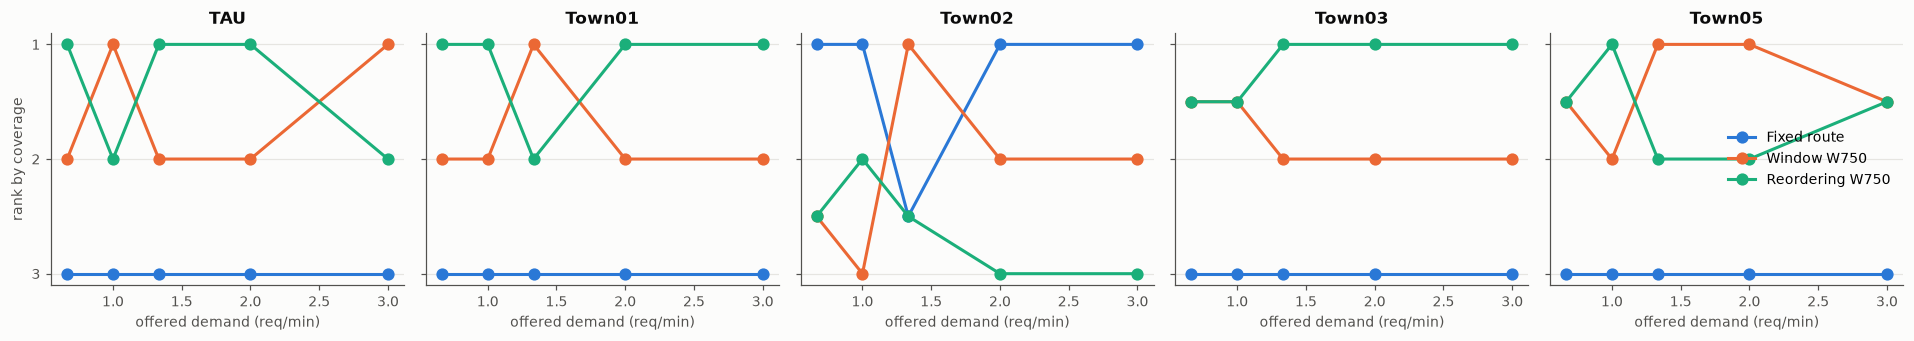

**Reordering W750 − Fixed route, in points of coverage** — the headroom routing buys, per rung.

offered_per_min,0.666667,1.000000,1.333333,2.000000,3.000000
TAU,46.7,54.4,45.6,24.4,13.3
Town01,36.7,14.4,16.7,27.8,25.6
Town02,-1.1,-1.1,0.0,-5.6,-4.4
Town03,26.7,21.1,16.7,27.8,25.6
Town05,45.6,23.3,24.4,14.4,15.6


In [10]:
if not HAVE_RUNS:
    display(Markdown("_Nothing to report until the sweep has run._"))
else:
    towns = sorted(frame["town"].unique())
    figure, axes = plt.subplots(
        1, len(towns), figsize=(3.5 * len(towns), 3.2), sharey=True,
        squeeze=False)
    for axis, town in zip(axes[0], towns):
        means = (frame[frame["town"] == town]
                 .pivot_table(index="offered_per_min", columns="policy",
                              values="served"))
        ranked = means.rank(axis=1, ascending=False)
        for colour, label in zip(SERIES, POLICY_LABELS):
            if label in ranked:
                axis.plot(ranked.index, ranked[label], marker="o",
                          markersize=7, lw=2, color=colour, label=label)
        axis.set_title(town)
        axis.set_xlabel("offered demand (req/min)")
        axis.set_yticks([1, 2, 3])
        axis.invert_yaxis()
        axis.grid(axis="y")
        axis.set_axisbelow(True)
    axes[0][0].set_ylabel("rank by coverage")
    axes[0][-1].legend()
    figure.tight_layout()
    plt.show()

    display(Markdown("**Reordering W750 − Fixed route, in points of "
                     "coverage** — the headroom routing buys, per rung."))
    pivot = frame.pivot_table(index=["town", "policy"],
                              columns="offered_per_min", values="served")
    gaps = {}
    for town in towns:
        if (town, "Reordering W750") in pivot.index \
                and (town, "Fixed route") in pivot.index:
            gaps[town] = (pivot.loc[(town, "Reordering W750")]
                          - pivot.loc[(town, "Fixed route")])
    display(pd.DataFrame(gaps).T.round(1))

## 7. Against the synthetic sweep

`synthetic-load-crossover.ipynb` ran this exact rate ladder on the 21-stop
planar map, and its answer was: the insertion advantage decays with load but
never inverts, and fixed route is completely load-invariant.

**This is a comparison of shape, not of level.** The two differ in almost
every other respect — 600 requests against 30, capacity 40 against 20,
patience 900 s against 750 s, and a synthetic map against real geometry. What
transfers, if anything, is the *direction and curvature*: does the advantage
decay here too, and does fixed route sit flat?

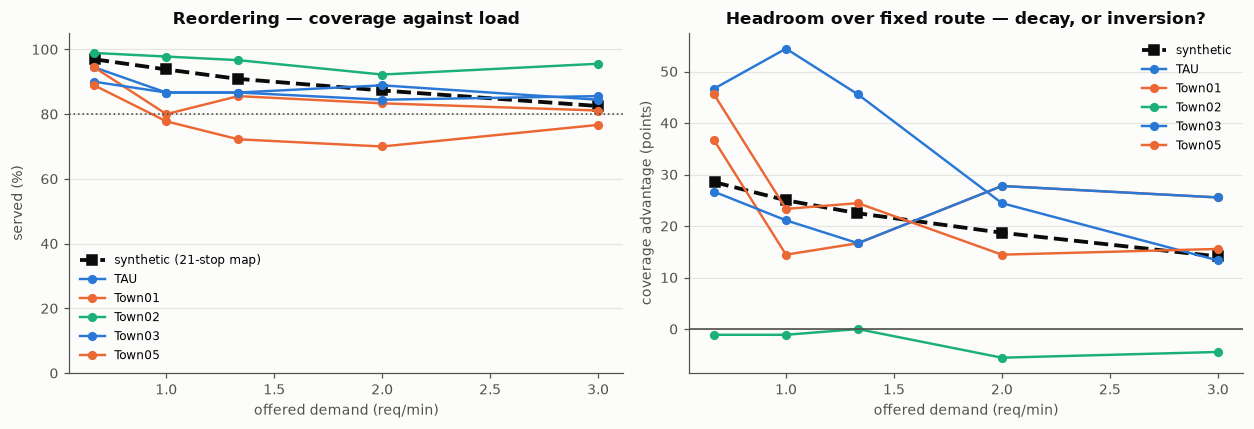

**Synthetic reference** (capacity 40, 600 requests, patience 900 s)

,Reordering,Fixed route,gap
0.67,96.9,68.4,28.5
1.00,93.8,68.8,25.0
1.33,90.9,68.4,22.5
2.00,87.3,68.6,18.7
3.00,82.5,68.4,14.1


The claim to test is that every line in the right panel **decays without crossing zero**. A town whose line crosses is one where fixed route is the better choice under load, which nothing in the project has found yet — check its saturation guard row and its repath count before believing it.

In [11]:
# Measured in synthetic-load-crossover.ipynb, impatient regime, 30 seeds a
# rung, capacity 40: mean coverage (%) for Reordering W900 and Fixed route.
SYNTHETIC = {
    0.67: {"Reordering": 96.9, "Fixed route": 68.4},
    1.00: {"Reordering": 93.8, "Fixed route": 68.8},
    1.33: {"Reordering": 90.9, "Fixed route": 68.4},
    2.00: {"Reordering": 87.3, "Fixed route": 68.6},
    3.00: {"Reordering": 82.5, "Fixed route": 68.4},
}

if not HAVE_RUNS:
    display(Markdown("_Nothing to report until the sweep has run._"))
else:
    rungs = sorted(SYNTHETIC)
    reference = pd.DataFrame(SYNTHETIC).T
    reference["gap"] = reference["Reordering"] - reference["Fixed route"]

    figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))
    axes[0].plot(rungs, reference["Reordering"], marker="s", markersize=7,
                 lw=2.5, color=INK, ls="--", label="synthetic (21-stop map)")
    for town in sorted(frame["town"].unique()):
        series = (frame[(frame["town"] == town)
                        & (frame["policy"] == "Reordering W750")]
                  .groupby("offered_per_min")["served"].mean().sort_index())
        axes[0].plot(series.index, series.values, marker="o", markersize=5,
                     lw=1.6, label=town)
    axes[0].axhline(GATE, ls=":", lw=1.1, color=INK_SOFT)
    axes[0].set_title("Reordering — coverage against load")
    axes[0].set_xlabel("offered demand (req/min)")
    axes[0].set_ylabel("served (%)")
    axes[0].set_ylim(0, 105)
    axes[0].grid(axis="y")
    axes[0].set_axisbelow(True)
    axes[0].legend(fontsize=8)

    axes[1].plot(rungs, reference["gap"], marker="s", markersize=7, lw=2.5,
                 color=INK, ls="--", label="synthetic")
    for town in sorted(frame["town"].unique()):
        block = frame[frame["town"] == town]
        best = (block[block["policy"] == "Reordering W750"]
                .groupby("offered_per_min")["served"].mean())
        base = (block[block["policy"] == "Fixed route"]
                .groupby("offered_per_min")["served"].mean())
        shared = sorted(set(best.index) & set(base.index))
        if shared:
            axes[1].plot(shared, (best - base).loc[shared], marker="o",
                         markersize=5, lw=1.6, label=town)
    axes[1].axhline(0, lw=1.1, color=INK_SOFT)
    axes[1].set_title("Headroom over fixed route — decay, or inversion?")
    axes[1].set_xlabel("offered demand (req/min)")
    axes[1].set_ylabel("coverage advantage (points)")
    axes[1].grid(axis="y")
    axes[1].set_axisbelow(True)
    axes[1].legend(fontsize=8)
    figure.tight_layout()
    plt.show()

    display(Markdown(
        "**Synthetic reference** (capacity 40, 600 requests, patience 900 s)"))
    display(reference.round(1))
    display(Markdown(
        "The claim to test is that every line in the right panel **decays "
        "without crossing zero**. A town whose line crosses is one where "
        "fixed route is the better choice under load, which nothing in the "
        "project has found yet — check its saturation guard row and its "
        "repath count before believing it."))

## 8. Health

CARLA failures are not rare enough to ignore. A run with repaths was
physically stuck at some point; a run with unroutable legs asked for a leg
`plan_route` could not build. Neither invalidates a run on its own, but a
rung whose coverage collapses *and* whose repath count jumps is a driving
failure wearing a demand failure's clothes.

In [12]:
if not HAVE_RUNS:
    display(Markdown("_Nothing to report until the sweep has run._"))
else:
    health = frame.groupby(["town", "offered_per_min"]).agg(
        runs=("repaths", "size"), repaths=("repaths", "sum"),
        unroutable=("unroutable", "sum"),
        stuck_runs=("repaths", lambda c: int((c > 0).sum())))
    display(Markdown("**Per town and rung.** `stuck_runs` is the count of "
                     "runs with at least one repath."))
    display(health)

    suspect = frame[(frame["repaths"] > 0) | (frame["unroutable"] > 0)]
    print(f"{len(suspect)} of {len(frame)} runs carry a repath or an "
          f"unroutable leg")
    if not suspect.empty:
        display(suspect.groupby(["town", "policy", "offered_per_min"])[
            ["repaths", "unroutable", "served"]].mean().round(1))

**Per town and rung.** `stuck_runs` is the count of runs with at least one repath.

runs  repaths  unroutable  stuck_runs
town   offered_per_min                                       
TAU    0.666667            9        0           0           0
       1.000000            9        0           0           0
       1.333333            9        0           0           0
       2.000000            9        0           0           0
       3.000000            9        0           0           0
Town01 0.666667            9        6           0           3
       1.000000            9        0           0           0
       1.333333            9        0           0           0
       2.000000            9        0           0           0
       3.000000            9        0           0           0
Town02 0.666667            9       20           0           7
       1.000000            9       12           0           5
       1.333333            9        9           0           3
       2.000000            9        8           0           4
       3.000000            9        8           0           5
Town03 0.666667            9        0           0           0
       1.000000            9        0           0           0
       1.333333            9        0           0           0
       2.000000            9        0           0           0
       3.000000            9        0           0           0
Town05 0.666667            9        0           0           0
       1.000000            9        0           0           0
       1.333333            9        0           0           0
       2.000000            9        0           0           0
       3.000000            9        0           0           0

27 of 225 runs carry a repath or an unroutable leg


repaths  unroutable  served
town   policy          offered_per_min                             
Town01 Reordering W750 0.666667             1.5         0.0    91.7
       Window W750     0.666667             3.0         0.0    70.0
Town02 Fixed route     0.666667             5.3         0.0   100.0
                       1.000000             3.3         0.0    98.9
                       1.333333             3.0         0.0    96.7
                       2.000000             2.0         0.0    97.8
                       3.000000             2.0         0.0   100.0
       Reordering W750 0.666667             1.0         0.0    98.3
                       1.000000             1.0         0.0    96.7
                       3.000000             1.0         0.0    93.3
       Window W750     0.666667             1.0         0.0    98.3
                       1.000000             1.0         0.0   100.0
                       2.000000             2.0         0.0    96.7
                       3.000000             1.0         0.0    96.7